In [ ]:
#сккачиваю напрямую датасет
!kaggle datasets download -d maysee/mushrooms-classification-common-genuss-images

!unzip -q mushrooms-classification-common-genuss-images.zip -d data/

!ls data/

Dataset URL: https://www.kaggle.com/datasets/maysee/mushrooms-classification-common-genuss-images
License(s): copyright-authors
mushrooms-classification-common-genuss-images.zip: Skipping, found more recently modified local copy (use --force to force download)
replace data/Mushrooms/Agaricus/000_ePQknW8cTp8.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: mushrooms  Mushrooms


In [ ]:

!ls -R data/ | head -n 30

data/:
mushrooms
Mushrooms

data/mushrooms:
Mushrooms

data/mushrooms/Mushrooms:
Agaricus
Amanita
Boletus
Cortinarius
Entoloma
Hygrocybe
Lactarius
Russula
Suillus

data/mushrooms/Mushrooms/Agaricus:
000_ePQknW8cTp8.jpg
001_2jP9N_ipAo8.jpg
002_hNh3aQSH-ZM.jpg
003_4AurAO4Jil8.jpg
004_Syi3NxxviC0.jpg
005_sUqyy4Yb9VY.jpg
006_1_E6AXBJqn4.jpg
009_mrv34Sn4WiQ.jpg
010_Rk1D3EG856g.jpg
011_WtefvQHAs0w.jpg
012_i_TOGa08rRE.jpg


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
from PIL import ImageFile
import os

ImageFile.LOAD_TRUNCATED_IMAGES = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Используется устройство: {device}")

data_dir = 'data/mushrooms/Mushrooms'


train_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
val_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


class SafeImageFolder(datasets.ImageFolder):
    def __getitem__(self, index):
        while True:
            try:
                path, target = self.samples[index]
                sample = self.loader(path)
                if self.transform is not None:
                    sample = self.transform(sample)
                if self.target_transform is not None:
                    target = self.target_transform(target)
                return sample, target
            except Exception:
                index = torch.randint(0, len(self.samples), (1,)).item()


full_dataset = SafeImageFolder(root=data_dir)
class_names = full_dataset.classes
num_classes = len(class_names)
print(f"Найдено классов ({num_classes}): {class_names}")

#разделяю на train/val
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])


train_dataset.dataset.transform = train_transforms
val_dataset.dataset.transform = val_transforms


batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
print(f"Всего изображений: {len(full_dataset)}. Обучающих: {train_size}, Проверочных: {val_size}")

#Transfer Learning
print("Загружаем модель...")
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for param in model.parameters():
    param.requires_grad = False
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, num_classes)
model = model.to(device)

#обучение
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)
num_epochs = 5

print("Начинаем обучение...")
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_acc = correct / total

    model.eval()
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_acc = val_correct / val_total
    print(f"Эпоха {epoch+1}/{num_epochs} | Loss: {running_loss/len(train_loader):.4f} | Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")

print("Обучение успешно завершено!")

Используется устройство: cuda
Найдено классов (9): ['Agaricus', 'Amanita', 'Boletus', 'Cortinarius', 'Entoloma', 'Hygrocybe', 'Lactarius', 'Russula', 'Suillus']
Всего изображений: 6714. Обучающих: 5371, Проверочных: 1343
Загружаем модель...
Начинаем обучение...
Эпоха 1/5 | Loss: 1.4761 | Train Acc: 0.4902 | Val Acc: 0.6374
Эпоха 2/5 | Loss: 1.0504 | Train Acc: 0.6552 | Val Acc: 0.6582
Эпоха 3/5 | Loss: 0.9232 | Train Acc: 0.6889 | Val Acc: 0.7029
Эпоха 4/5 | Loss: 0.8484 | Train Acc: 0.7062 | Val Acc: 0.7051
Эпоха 5/5 | Loss: 0.8151 | Train Acc: 0.7187 | Val Acc: 0.7066
Обучение успешно завершено!


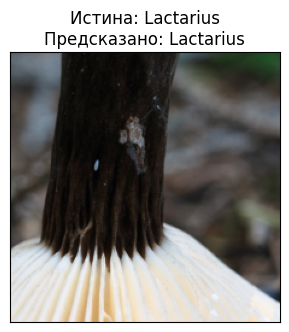

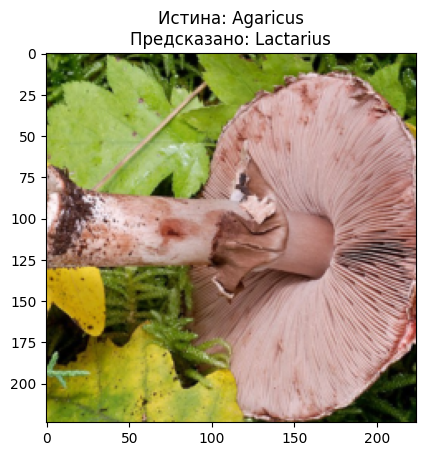

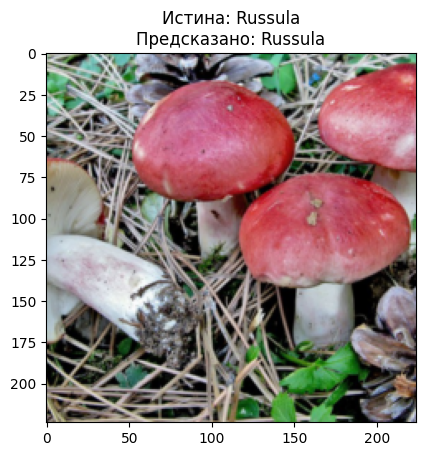

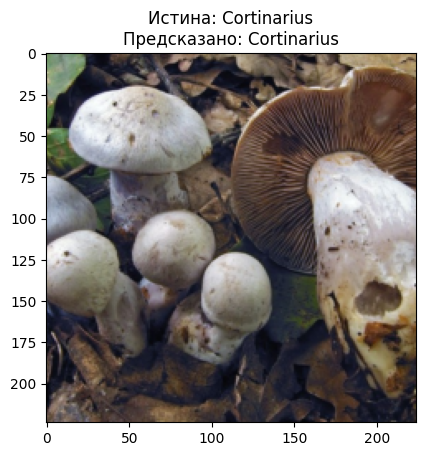

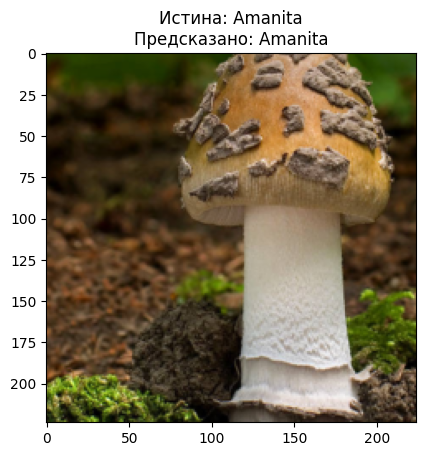

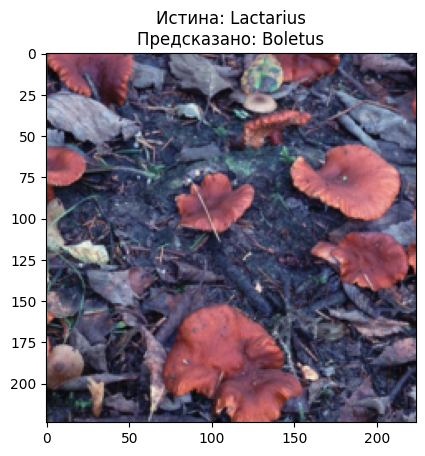

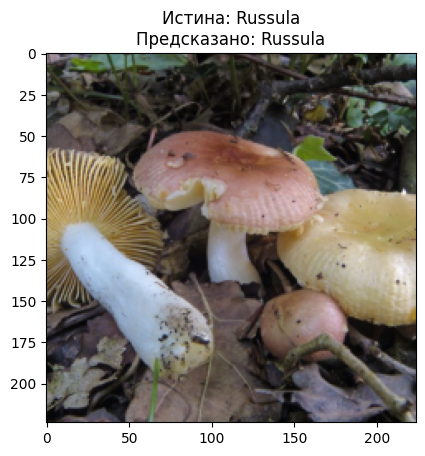

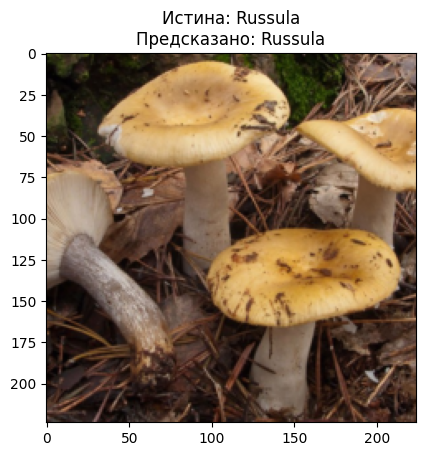

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def imshow(inp, title=None):
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)


images, labels = next(iter(val_loader))
images, labels = images.to(device), labels.to(device)


model.eval()
with torch.no_grad():
    outputs = model(images)
    _, preds = torch.max(outputs, 1)


fig = plt.figure(figsize=(16, 8))
for i in range(8):
    ax = fig.add_subplot(2, 4, i+1, xticks=[], yticks=[])
    imshow(images.cpu()[i], title=f"Истина: {class_names[labels[i]]}\nПредсказано: {class_names[preds[i]]}")
    color = 'green' if preds[i] == labels[i] else 'red'
    ax.title.set_color(color)
plt.show()